### Loading data and libraries

In [2]:
# Load libraries.
import pandas as pd
import numpy as np

# Visualisation libraries.
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [3]:
# Loading the dataset
df = pd.read_csv("UsArrests.csv")
df.head(10)

,City,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6
5,Colorado,7.9,204,78,38.7
6,Connecticut,3.3,110,77,11.1
7,Delaware,5.9,238,72,15.8
8,Florida,15.4,335,80,31.9
9,Georgia,17.4,211,60,25.8


### Exploring the data

In [4]:
# The shape of the dataset
df.shape

(50, 5)

In [5]:
# Count missing values
missing = df.isnull().sum()
relevant_missing = pd.DataFrame(missing, columns=["missing"])
relevant_missing


,missing
City,0
Murder,0
Assault,0
UrbanPop,0
Rape,0


In [6]:
# Examine data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   City      50 non-null     str    
 1   Murder    50 non-null     float64
 2   Assault   50 non-null     int64  
 3   UrbanPop  50 non-null     int64  
 4   Rape      50 non-null     float64
dtypes: float64(2), int64(2), str(1)
memory usage: 2.1 KB


In [7]:
# Summary of statistics for the numeric features
df.describe()

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


**Data Exploration and Preprocessing Motivation**

The dataset has 50 rows and 5 columns, there are no missing rows and there are four numeric columns which are stored as numeric data types hence there is no conversion which is required.

City is an identifier, not a measurement hence it is dropped before any numeric analysis. From the summary of statistics of the numerical features, the features have differing scales as Assault ranges up to hundreds while murder and rape ranges from single digits up to 40s. PCA and distance based methods are scale sensitive hence there is a motivation for standardization of the numeric features before performing PCA and clustering.

### Peforming a correlation Analysis

In [8]:
# Dropping the city column, it is not measurement, in preparation for the correlation plot
corr_df = df.drop(["City"], axis=1)
labels = corr_df.columns

# Correlation matrix of the original (unscaled) features
correlations = corr_df.corr()
correlations

,Murder,Assault,UrbanPop,Rape
Murder,1.000000,0.801873,0.069573,0.563579
Assault,0.801873,1.000000,0.258872,0.665241
UrbanPop,0.069573,0.258872,1.000000,0.411341
Rape,0.563579,0.665241,0.411341,1.000000


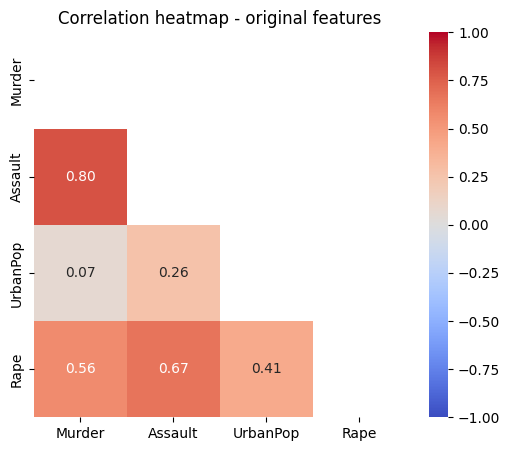

In [9]:
# Plot correlation heatmap - shows the positive and negative correlations between all features
mask_ut = np.triu(np.ones(correlations.shape)).astype(bool)

plt.figure(figsize=(6, 5))
sns.heatmap(correlations, mask=mask_ut, cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f")
plt.title("Correlation heatmap - original features")
plt.show()

**Interpretation of the results** 

Assault is strongly correlating with Murder(~0.80), which is indicating that most murders emanate from the assault, there is a considerable correlation observed between Rape and Assault(~0.67), indicating that some rape cases involve assault which is expected. There is no correlation between Urban population and Murder, which indicates that the size of population does not influence the rate of Murder in all the listed cities.

### Plotting and interpreting the biplot of the first two components

In [10]:
# Selecting the numerical components for PCA
X = df.drop(["City"],axis=1).values

# Standardizing the data
X_std = StandardScaler().fit_transform(X)

std_pca = PCA()
X_std_trans = std_pca.fit_transform(X_std)

df_std_pca = pd.DataFrame(X_std_trans, columns=[f"PC{i+1}" for i in range(X_std_trans.shape[1])])
df_std_pca.insert(0, "City", df["City"].values)
df_std_pca.head()

,City,PC1,PC2,PC3,PC4
0,Alabama,0.985566,-1.133392,-0.444269,-0.156267
1,Alaska,1.950138,-1.073213,2.040003,0.438583
2,Arizona,1.763164,0.745957,0.054781,0.834653
3,Arkansas,-0.141420,-1.119797,0.114574,0.182811
4,California,2.523980,1.542934,0.598557,0.341996


In [11]:
# Create biplot function
def biplot(score, coeff, labels=None, species=None, groups=None):
    xs = score[:, 0]
    ys = score[:, 1]
    n = coeff.shape[0]
    scalex = 1.0 / (xs.max() - xs.min())
    scaley = 1.0 / (ys.max() - ys.min())

    fig, ax = plt.subplots(figsize=(8, 7))

    if groups is not None:
        for sp in pd.unique(groups):
            mask = groups == g
            ax.scatter(xs[mask] * scalex, ys[mask] * scaley, s=15, label=g)
        ax.legend()
    else:
        ax.scatter(xs * scalex, ys * scaley, s=15)

    for i in range(n):
        ax.arrow(0, 0, coeff[i, 0], coeff[i, 1], color='r', head_width=0.02, alpha=0.5)
        if labels is None:
            ax.text(coeff[i, 0] * 1.15, coeff[i, 1] * 1.15, "Var" + str(i + 1),
                    color='green', ha='center', va='center')
        else:
            ax.text(coeff[i, 0] * 1.15, coeff[i, 1] * 1.15, labels[i],
                    color='g', ha='center', va='center')

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("Biplot of PCA-transformed Cities data")
    plt.grid()

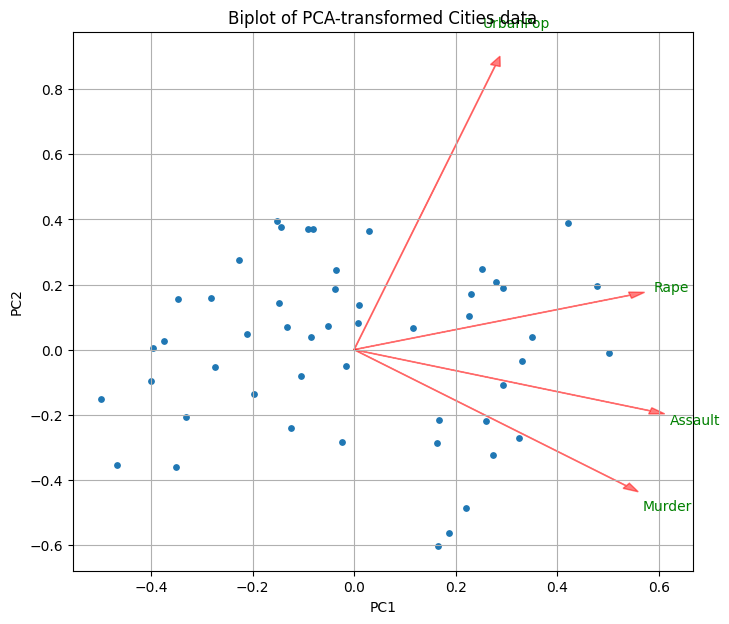

In [12]:
# Printing out the biplot with the transformed data
biplot(X_std_trans[:, 0:2], np.transpose(std_pca.components_[0:2, :]), list(labels))
plt.show()

The three crime variables (Murder, Assault, Rape) all point in a similar direction and load heavily onto PC1, confirming what the correlation showed. Urbanpop points in a noticeably different direction, loading mostly onto PC2, independent of crime axis.

### Selecting the number of principal components

In [13]:
# Explained variance ratio for each component
explained_var = std_pca.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var)

pd.DataFrame({
    "component": [f"PC{i+1}" for i in range(len(explained_var))],
    "explained_variance_ratio": explained_var,
    "cumulative_explained_variance": cum_explained_var
})

,component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.620060,0.620060
1,PC2,0.247441,0.867502
2,PC3,0.089141,0.956642
3,PC4,0.043358,1.000000


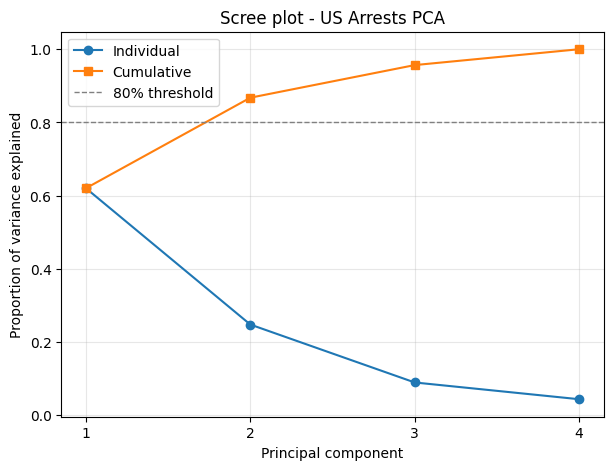

In [14]:
# Scree plot of explained variance
plt.figure(figsize=(7, 5))
plt.plot(range(1, len(explained_var) + 1), explained_var, marker='o', label="Individual")
plt.plot(range(1, len(explained_var) + 1), cum_explained_var, marker='s', label="Cumulative")
plt.axhline(0.8, color='gray', linestyle='--', linewidth=1, label="80% threshold")
plt.xticks(range(1, len(explained_var) + 1))
plt.xlabel("Principal component")
plt.ylabel("Proportion of variance explained")
plt.title("Scree plot - US Arrests PCA")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Justification**

With only 4 standardized features, PCA produces 4 components, from the explained variance table.
 - PC1 explains 62% of the total variances, and PC2 adds a further 25%, so the first two components together already explain 87% of the total variance
 - PC3 and PC4 each add only a small amount (~8% and ~4% respectively), and the scree plot elbows sharply after PC2

We retain the first two principal components for further analysis as they capture majority (~87%) of the variance in the data while reducing dimensionality from 4 to 2.

In [15]:
# Keep the first two principal components for downstream clustering
n_components = 2
X_pca = X_std_trans[:, :n_components]
X_pca.shape

(50, 2)

### Applying the two clustering techniques

In [16]:
# Choosing k for K-means using silhouette scores
sil_scores = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_labels = km.fit_predict(X_pca)
    sil_scores[k] = silhouette_score(X_pca, km_labels)

pd.Series(sil_scores, name="silhouette_score").to_frame()

,silhouette_score
2,0.475803
3,0.401361
4,0.443978
5,0.407866
6,0.395565
7,0.373304


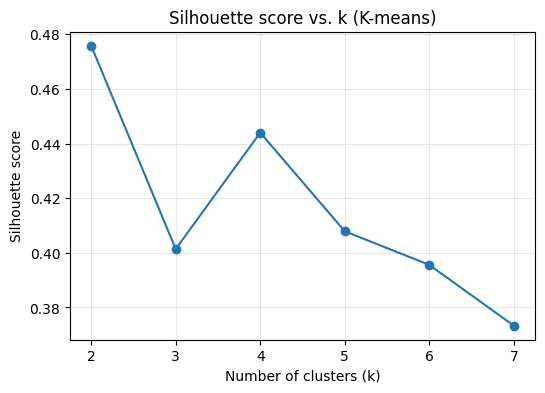

In [17]:
plt.figure(figsize=(6, 4))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score vs. k (K-means)")
plt.grid(alpha=0.3)
plt.show()

The best k is represented by the k with the highest silhouette score which is 2 in this case.

**Technique 1: K means clustering technique**

In [20]:
best_k = 2
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

df_clusters = df.copy()
df_clusters["KMeans_Cluster"] = kmeans_labels
df_clusters.head()

,City,Murder,Assault,UrbanPop,Rape,KMeans_Cluster
0,Alabama,13.2,236,58,21.2,1
1,Alaska,10.0,263,48,44.5,1
2,Arizona,8.1,294,80,31.0,1
3,Arkansas,8.8,190,50,19.5,0
4,California,9.0,276,91,40.6,1


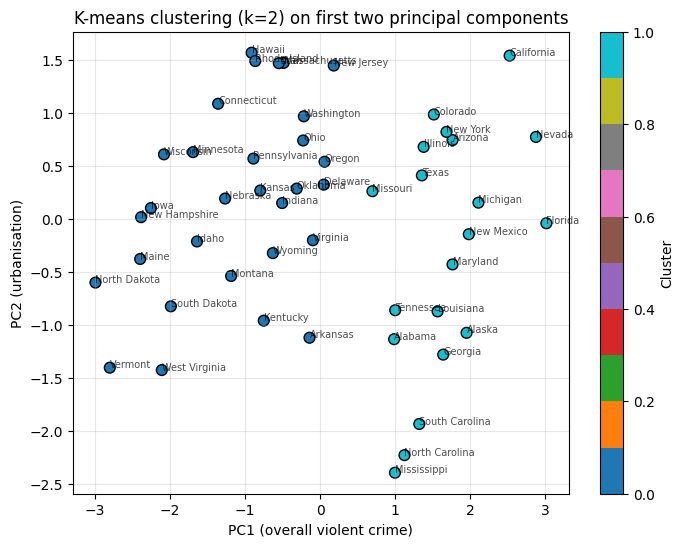

In [21]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="tab10", s=60, edgecolor='k')
for i, city in enumerate(df["City"]):
    plt.annotate(city, (X_pca[i, 0], X_pca[i, 1]), fontsize=7, alpha=0.7)
plt.xlabel("PC1 (overall violent crime)")
plt.ylabel("PC2 (urbanisation)")
plt.title(f"K-means clustering (k={best_k}) on first two principal components")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.3)
plt.show()

In [22]:
# Mean feature values per K-means cluster (in original units) - helps interpret the clusters
df_clusters.groupby("KMeans_Cluster")[["Murder", "Assault", "UrbanPop", "Rape"]].mean().round(2)

,Murder,Assault,UrbanPop,Rape
KMeans_Cluster,,,,
0,4.87,114.43,63.63,15.94
1,12.16,255.25,68.40,29.16


**Technique 2: Agglomerative (hierarchical) Clustering**

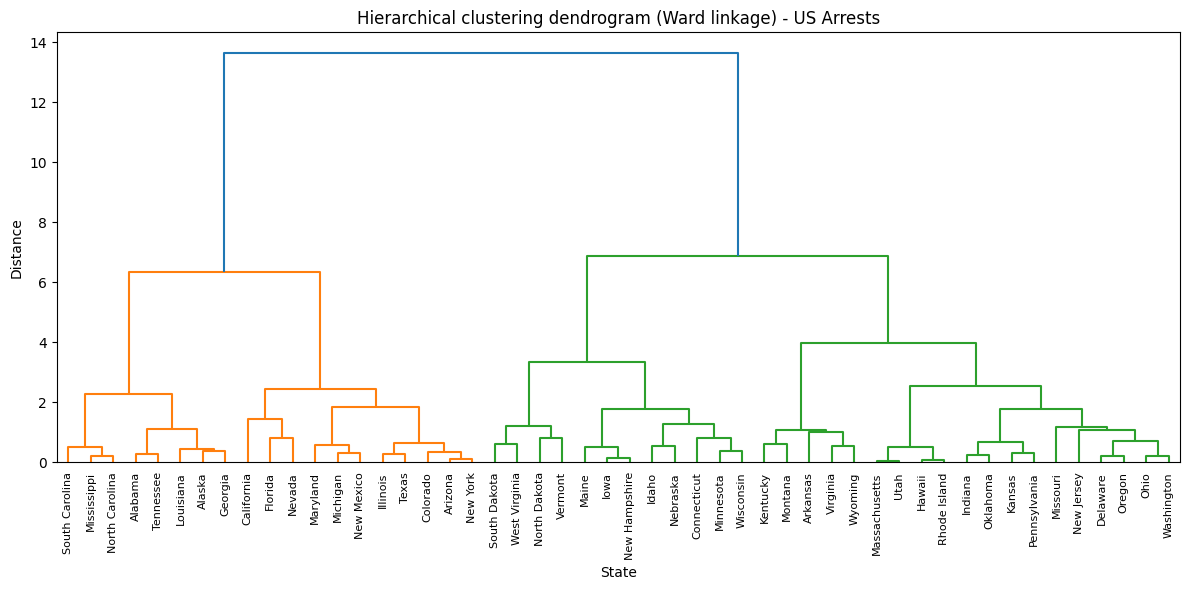

In [24]:
# Dendrogram on the PCA-reduced data
linked = linkage(X_pca, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked, labels=df["City"].values, leaf_rotation=90, leaf_font_size=8)
plt.title("Hierarchical clustering dendrogram (Ward linkage) - US Arrests")
plt.xlabel("State")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [25]:
agg = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
agg_labels = agg.fit_predict(X_pca)

df_clusters["Agglomerative_Cluster"] = agg_labels

sil_agg = silhouette_score(X_pca, agg_labels)
print(f"Agglomerative clustering silhouette score (k={best_k}): {sil_agg:.3f}")
df_clusters.head()

Agglomerative clustering silhouette score (k=2): 0.470


,City,Murder,Assault,UrbanPop,Rape,KMeans_Cluster,Agglomerative_Cluster
0,Alabama,13.2,236,58,21.2,1,1
1,Alaska,10.0,263,48,44.5,1,1
2,Arizona,8.1,294,80,31.0,1,1
3,Arkansas,8.8,190,50,19.5,0,0
4,California,9.0,276,91,40.6,1,1


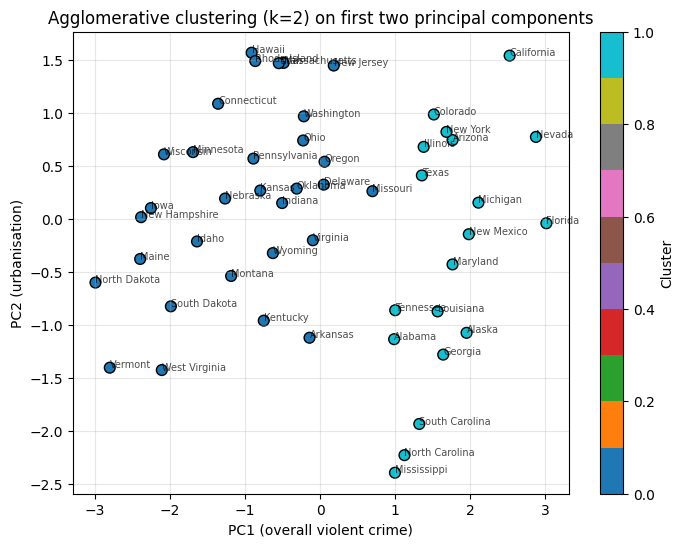

In [26]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap="tab10", s=60, edgecolor='k')
for i, city in enumerate(df["City"]):
    plt.annotate(city, (X_pca[i, 0], X_pca[i, 1]), fontsize=7, alpha=0.7)
plt.xlabel("PC1 (overall violent crime)")
plt.ylabel("PC2 (urbanisation)")
plt.title(f"Agglomerative clustering (k={best_k}) on first two principal components")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.3)
plt.show()

In [27]:
# Mean feature values per Agglomerative cluster (in original units)
df_clusters.groupby("Agglomerative_Cluster")[["Murder", "Assault", "UrbanPop", "Rape"]].mean().round(2)

,Murder,Assault,UrbanPop,Rape
Agglomerative_Cluster,,,,
0,5.00,116.48,63.84,16.34
1,12.33,259.32,68.32,29.22


**Analysis of the clusters**

Both K means and agglomerative clustering, applied to the same PCA-reduced data(PC1 and PC2), agree with one another, most states fall into the corresponding clusters under both methods, which gives us confidence that the grouping reflects the real structure in the data rather than of one particular algorithm.